# Wang Transform MLE Tutorial: Pooled and Hierarchical Estimation

This notebook walks through synthetic calibration, statistical inference, and
position-sizing Greeks for prediction markets using
`oracle3.pricing.wang_mle.WangMLE` and `oracle3.pricing.greeks`.

- **Reference model:** Wang Transform probit-offset decomposition from Yang
  (2026), *Pricing Prediction Markets: Risk Premiums, Incomplete Markets, and a
  Decomposition Framework*.
- **Oracle3 citation:** [DOI 10.5281/zenodo.20062549](https://doi.org/10.5281/zenodo.20062549)
- **Prerequisites:** `numpy`, `scipy`, `matplotlib`, and `oracle3` (installed
  from the repository checkout or available on `PYTHONPATH`).

> **Note:** All contracts, prices, covariates, and outcomes in this notebook are
> **synthetic/simulated tutorial data** generated for educational purposes. None
> of the outputs represent live trading performance or real market returns.

In [1]:
from __future__ import annotations

import importlib.util
import sys
from pathlib import Path

if importlib.util.find_spec('oracle3') is None:
    for _candidate in (Path.cwd(), Path.cwd().parent):
        if (_candidate / 'oracle3').is_dir():
            sys.path.insert(0, str(_candidate))
            break

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
from scipy.stats import norm  # noqa: E402

from oracle3.pricing.greeks import (  # noqa: E402
    compute_greeks_table,
    delta_lambda,
    kelly_fraction,
)
from oracle3.pricing.wang_mle import (  # noqa: E402
    HIER_BETA_CONSTANT,
    HIER_BETA_EXTREMITY,
    HIER_BETA_LN_DURATION,
    HIER_BETA_LN_VOLUME,
    HIER_BETA_SPREAD,
    LAMBDA_KALSHI,
    LAMBDA_MANIFOLD,
    LAMBDA_METACULUS,
    LAMBDA_POLYMARKET,
    LAMBDA_POOLED,
    WangMLE,
)

rng = np.random.default_rng(42)

## 1. Synthetic Data Generation

Under the Wang Transform pricing model, market-implied prices $p_{\text{mkt}}$
are a probit-space shift of the physical resolution probabilities $p^*$:

$$p_{\text{mkt}} = \Phi\bigl(\Phi^{-1}(p^*) + \lambda\bigr)$$

When $\lambda > 0$, market prices exceed true physical probabilities
($p_{\text{mkt}} > p^*$), representing positive risk compensation for liquidity
providers or systematic overpricing of YES contracts. Below we simulate
$N = 5{,}000$ synthetic resolved contracts with `true_lambda = 0.18` using
`scipy.stats.norm.ppf` and `scipy.stats.norm.cdf`, and draw binary outcomes
$y_i \sim \text{Bernoulli}(p^*_i)$.

In [2]:
n_contracts = 5000
true_lambda = 0.18

p_physical = rng.uniform(0.10, 0.90, size=n_contracts)
p_market = norm.cdf(norm.ppf(p_physical) + true_lambda)
outcomes = (rng.uniform(size=n_contracts) < p_physical).astype(float)

print(f'Simulated contracts: N = {n_contracts:,}')
print(f'True lambda:         {true_lambda:.4f}')
print(f'Mean physical prob:  {p_physical.mean():.4f}')
print(f'Mean market price:   {p_market.mean():.4f}')
print(f'Realized YES rate:   {outcomes.mean():.4f}')
print(f'Mean implied edge:   {(p_market - p_physical).mean():.4f}')

Simulated contracts: N = 5,000
True lambda:         0.1800
Mean physical prob:  0.4965
Mean market price:   0.5554
Realized YES rate:   0.5052
Mean implied edge:   0.0589


## 2. Pooled MLE Estimation

We fit the pooled model with `WangMLE().fit(prices=..., outcomes=...)`. Passing
no covariates estimates a single scalar $\lambda$ across all contracts using
the probit-offset log-likelihood $\Pr(y_i = 1 \mid p_i) = \Phi(\Phi^{-1}(p_i) - \lambda)$.

In [3]:
mle_pooled = WangMLE()
result_pooled = mle_pooled.fit(prices=p_market, outcomes=outcomes)

z_diff = (result_pooled.lambda_hat - true_lambda) / result_pooled.se_robust[0]
within_2se = (
    abs(result_pooled.lambda_hat - true_lambda) <= 2.0 * result_pooled.se_robust[0]
)
assert result_pooled.converged
assert within_2se

print(f'converged:      {result_pooled.converged}')
print(f'lambda_hat:     {result_pooled.lambda_hat:.4f}')
print(f'se_fisher[0]:   {result_pooled.se_fisher[0]:.4f}')
print(f'se_robust[0]:   {result_pooled.se_robust[0]:.4f}')
print(f'z_stat(0):      {result_pooled.z_stat(0):.2f}')
print(f'p_value(0):     {result_pooled.p_value(0):.2e}')
print(f'z_diff vs true: {z_diff:+.2f} (within 2.0 robust SEs: {within_2se})')
print()
print(result_pooled.summary_table())

converged:      True
lambda_hat:     0.1536
se_fisher[0]:   0.0191
se_robust[0]:   0.0191
z_stat(0):      8.03
p_value(0):     8.88e-16
z_diff vs true: -1.38 (within 2.0 robust SEs: True)

Wang Transform MLE (N=5000, p=1)
Log-likelihood: -2898.73  AIC: 5799.46  BIC: 5805.98  Pseudo-R²: 0.0110

Variable                   Coef   SE(Fisher)   SE(Robust)        z          p
--------------------------------------------------------------------------
lambda                   0.1536       0.0191       0.0191     8.03  8.88e-16 ***


In [4]:
priors = [
    ('LAMBDA_POLYMARKET', LAMBDA_POLYMARKET, 'Polymarket real-money'),
    ('LAMBDA_KALSHI', LAMBDA_KALSHI, 'Kalshi real-money'),
    ('LAMBDA_POOLED', LAMBDA_POOLED, 'Pooled (291K contracts)'),
    ('LAMBDA_METACULUS', LAMBDA_METACULUS, 'Metaculus crowd forecasts'),
    ('LAMBDA_MANIFOLD', LAMBDA_MANIFOLD, 'Manifold play-money'),
]

p_mid_mkt = float(norm.cdf(result_pooled.lambda_hat))
print(f'Simulated lambda_hat = {result_pooled.lambda_hat:.4f}')
print(f'At p* = 0.50, market price = Phi(lambda_hat) = {p_mid_mkt:.4f}\n')
print('Prior Constant          Value   Description')
print('-' * 58)
for name, val, desc in priors:
    print(f'{name:<20} {val:>8.3f}   {desc}')

Simulated lambda_hat = 0.1536
At p* = 0.50, market price = Phi(lambda_hat) = 0.5610

Prior Constant          Value   Description
----------------------------------------------------------
LAMBDA_POLYMARKET       0.166   Polymarket real-money
LAMBDA_KALSHI           0.187   Kalshi real-money
LAMBDA_POOLED           0.183   Pooled (291K contracts)
LAMBDA_METACULUS        0.287   Metaculus crowd forecasts
LAMBDA_MANIFOLD        -0.218   Manifold play-money


### Interpreting the Magnitude Against `wang_mle.py` Empirical Priors

- **Positive $\lambda$ (real-money and forecast markets):** Our synthetic
  estimate (`0.1536`, recovering `true_lambda = 0.18` within 2 robust SEs)
  sits in the same range as the empirical priors at the top of
  `oracle3/pricing/wang_mle.py`: `LAMBDA_POLYMARKET = 0.166`,
  `LAMBDA_POOLED = 0.183`, and `LAMBDA_KALSHI = 0.187` (with
  `LAMBDA_METACULUS = 0.287`).
- **Economic meaning:** At a 50/50 physical event ($p^* = 0.50$,
  $\Phi^{-1}(0.50) = 0$), $\lambda \approx 0.15\text{--}0.19$ maps to a YES
  market price of $\Phi(\lambda) \approx \$0.56\text{--}\$0.58$ — roughly 6 to 8
  cents of systematic risk compensation per \$1 binary contract.
- **Sign reversal on play-money:** By contrast, `LAMBDA_MANIFOLD = -0.218` is
  negative, reflecting systematic underpricing rather than positive risk
  compensation on play-money markets.

## 3. Hierarchical MLE with Contract Covariates

Risk premiums vary across market microstructure conditions. Following Yang (2026)
and `TestHierarchicalMLE` in `tests/test_wang_mle.py`, we model contract-level
distortion as a linear function of observable covariates:

$$\lambda_i = \beta_0 + \beta_1 \ln(1 + \text{volume}_i) + \beta_2 \ln(1 + \text{duration\_hours}_i) + \beta_3 |p_{\text{mkt}, i} - 0.5|$$

We simulate 5,000 contracts using the empirical coefficients
(`HIER_BETA_CONSTANT = 0.2590`, `HIER_BETA_LN_VOLUME = -0.0716`,
`HIER_BETA_LN_DURATION = 0.1431`, `HIER_BETA_EXTREMITY = -0.4772`), solve the
forward pricing map consistently so $|p_{\text{mkt}, i} - 0.5|$ in the DGP
matches `build_design_matrix`, and draw outcomes from $p^*$.

Two implementation notes for `WangMLE`:
1. `build_design_matrix` uses the keyword `durations_hours=` (not `durations=`).
2. `build_design_matrix` stores column names in `self._last_covariate_names`, so
   we create a **fresh** `WangMLE()` instance for the hierarchical fit to keep
   pooled and hierarchical state isolated.

In [5]:
n_hier = 5000
p_phys_hier = rng.uniform(0.15, 0.85, size=n_hier)
volumes = np.exp(rng.uniform(np.log(100.0), np.log(50000.0), size=n_hier))
durations_hours = np.exp(rng.uniform(np.log(6.0), np.log(720.0), size=n_hier))

true_beta = np.array(
    [
        HIER_BETA_CONSTANT,
        HIER_BETA_LN_VOLUME,
        HIER_BETA_LN_DURATION,
        HIER_BETA_EXTREMITY,
    ]
)

z_phys_hier = norm.ppf(p_phys_hier)
ln_vol = np.log(1.0 + volumes)
ln_dur = np.log(1.0 + durations_hours)

# Solve p_mkt = Phi(Phi^{-1}(p*) + X(p_mkt) @ true_beta) via fixed-point iteration
p_mkt_hier = p_phys_hier.copy()
for _ in range(30):
    lam_hier = (
        true_beta[0]
        + true_beta[1] * ln_vol
        + true_beta[2] * ln_dur
        + true_beta[3] * np.abs(p_mkt_hier - 0.5)
    )
    p_mkt_hier = norm.cdf(z_phys_hier + lam_hier)

outcomes_hier = (rng.uniform(size=n_hier) < p_phys_hier).astype(float)

# Use a fresh WangMLE() instance so _last_covariate_names stays isolated
mle_hier = WangMLE()
X_hier = mle_hier.build_design_matrix(
    volumes=volumes,
    durations_hours=durations_hours,
    prices=p_mkt_hier,
)
result_hier = mle_hier.fit(
    prices=p_mkt_hier,
    outcomes=outcomes_hier,
    covariates=X_hier,
)

assert result_hier.converged
print(result_hier.summary_table())
print()
print('Covariate             True  Estimated  SE(Robust)   z-diff')
print('-' * 58)
for name, b_true, b_hat, se_r in zip(
    result_hier.covariate_names,
    true_beta,
    result_hier.beta,
    result_hier.se_robust,
):
    z_err = (b_hat - b_true) / se_r
    assert abs(z_err) <= 2.5
    print(f'{name:<16} {b_true:>9.4f} {b_hat:>10.4f} {se_r:>11.4f} {z_err:>+8.2f}')

print(f'\nNote: HIER_BETA_SPREAD = {HIER_BETA_SPREAD:.4f} (n.s. in paper) is omitted.')

Wang Transform MLE (N=5000, p=4)
Log-likelihood: -3018.03  AIC: 6044.07  BIC: 6070.14  Pseudo-R²: 0.0465

Variable                   Coef   SE(Fisher)   SE(Robust)        z          p
--------------------------------------------------------------------------
constant                 0.3652       0.1059       0.1045     3.49  4.77e-04 ***
ln(1+volume)            -0.0707       0.0104       0.0103    -6.87  6.21e-12 ***
ln(1+duration)           0.1239       0.0139       0.0140     8.87  0.00e+00 ***
|p-0.5|                 -0.5531       0.1746       0.1751    -3.16  1.58e-03 **

Covariate             True  Estimated  SE(Robust)   z-diff
----------------------------------------------------------
constant            0.2590     0.3652      0.1045    +1.02
ln(1+volume)       -0.0716    -0.0707      0.0103    +0.09
ln(1+duration)      0.1431     0.1239      0.0140    -1.38
|p-0.5|            -0.4772    -0.5531      0.1751    -0.43

Note: HIER_BETA_SPREAD = 0.1273 (n.s. in paper) is omitted.


## 4. Likelihood-Ratio Test (Pooled vs. Hierarchical)

To test whether covariate-dependent distortion improves fit over a single
constant $\lambda$, we fit the nested restricted (pooled) model on the **same**
hierarchical dataset and compare both fits with
`WangMLE().lr_test(result_full, result_restricted)`.

In [6]:
mle_restricted = WangMLE()
result_restricted = mle_restricted.fit(prices=p_mkt_hier, outcomes=outcomes_hier)

chi2_stat, lr_pvalue, df = WangMLE().lr_test(result_hier, result_restricted)
assert df == X_hier.shape[1] - 1
assert chi2_stat > 0
assert lr_pvalue < 0.05

print(
    f'Restricted log-likelihood (pooled, p={result_restricted.n_params}): '
    f'{result_restricted.log_likelihood:.2f} | AIC={result_restricted.aic:.2f}'
)
print(
    f'Full log-likelihood       (hier,   p={result_hier.n_params}): '
    f'{result_hier.log_likelihood:.2f} | AIC={result_hier.aic:.2f}'
)
print(f'LR test (chi2_stat, p_value, df) = ({chi2_stat:.4f}, {lr_pvalue:.4e}, {df})')

Restricted log-likelihood (pooled, p=1): -3081.40 | AIC=6164.79
Full log-likelihood       (hier,   p=4): -3018.03 | AIC=6044.07
LR test (chi2_stat, p_value, df) = (126.7272, 0.0000e+00, 3)


### What the Likelihood-Ratio Test Tells a Researcher or Trader

With a large $\chi^2$ statistic on $\text{df} = 3$ degrees of freedom
($p \ll 0.001$; `lr_test` prints `0.0000e+00` due to float64 underflow below
$10^{-16}$) and substantially lower AIC, we strongly reject the constant-$\lambda$
null hypothesis. Risk premiums are **not** uniform across contracts: higher
trading volume compresses $\lambda$ toward zero (consistent with `HIER_BETA_LN_VOLUME < 0`),
longer duration increases $\lambda$ (`HIER_BETA_LN_DURATION > 0`), and contracts
away from 50% carry smaller probit shifts (`HIER_BETA_EXTREMITY < 0`).

## 5. Model Greeks and Position Sizing Visualization

Using the fitted pooled `lambda_hat` from Section 2, we inspect
`oracle3.pricing.greeks`:
- `compute_greeks_table(prices, lam)` returns per-price premiums, Greeks, and
  fee-adjusted Kelly fractions.
- `delta_lambda(p_physical, lam)` expects the **physical** probability
  $p^* = \Phi(\Phi^{-1}(p_{\text{mkt}}) - \lambda)$ and equals
  $\partial p_{\text{mkt}} / \partial \lambda = \phi(\Phi^{-1}(p^*) + \lambda)$.
- `kelly_fraction(p_market, lam, fee_rate=0.005)` expects the **market** price
  $p_{\text{mkt}}$, deducts round-trip fees (`2 * fee_rate`, default `0.01`),
  and caps fractions to `[-0.25, 0.25]`. (This scalar `fee_rate` is a
  tutorial helper default; production venue fee schedules live in `oracle3.fees`.)

In [7]:
lam_hat = result_pooled.lambda_hat
sample_prices = [0.1, 0.25, 0.5, 0.75, 0.9]
greeks_rows = compute_greeks_table(sample_prices, lam=lam_hat)

header = ' p_mkt   p_phys   premium  delta_lam     kelly     edge'
print(f'Greeks table at pooled lambda_hat = {lam_hat:.4f} (default fee_rate = 0.005)')
print(header)
print('-' * len(header))
for row in greeks_rows:
    pm = row['p_market']
    pp = row['p_physical']
    prem = row['premium']
    dlam = row['delta_lambda']
    kf = row['kelly']
    edge = row['implied_edge']
    print(f'{pm:6.2f} {pp:8.4f} {prem:+9.4f} {dlam:10.4f} {kf:+9.4f} {edge:8.4f}')

Greeks table at pooled lambda_hat = 0.1536 (default fee_rate = 0.005)
 p_mkt   p_phys   premium  delta_lam     kelly     edge
-------------------------------------------------------
  0.10   0.0756   +0.0244     0.1755   -0.1437   0.0244
  0.25   0.2038   +0.0462     0.3178   -0.1447   0.0462
  0.50   0.4390   +0.0610     0.3989   -0.1021   0.0610
  0.75   0.6988   +0.0512     0.3178   -0.0550   0.0512
  0.90   0.8703   +0.0297     0.1755   -0.0218   0.0297


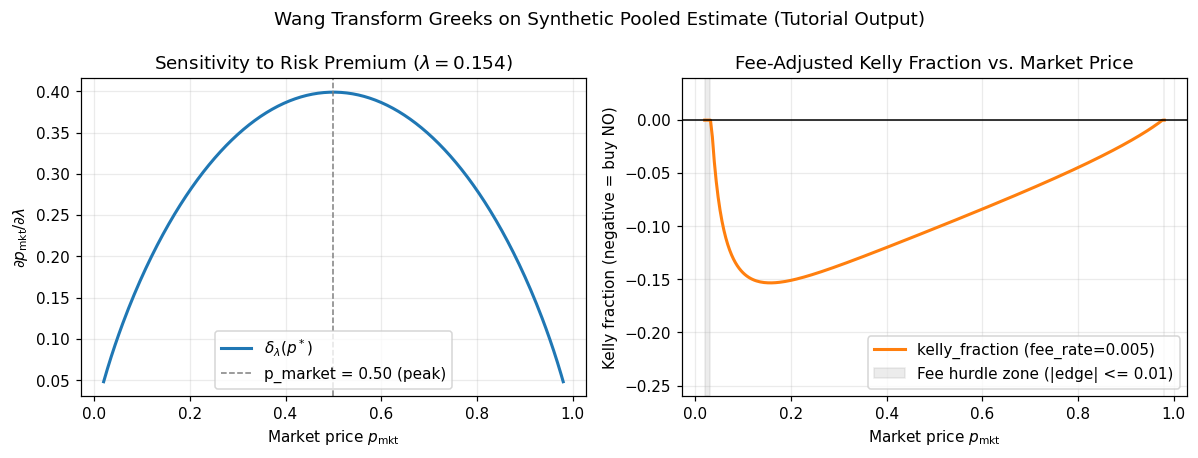

In [8]:
p_grid = np.linspace(0.02, 0.98, 241)
table_grid = compute_greeks_table(p_grid.tolist(), lam=lam_hat)

p_phys_grid = norm.cdf(norm.ppf(p_grid) - lam_hat)
delta_lam_vals = np.array([delta_lambda(float(p), lam_hat) for p in p_phys_grid])
kelly_vals = np.array([kelly_fraction(float(p), lam_hat) for p in p_grid])

assert np.allclose(
    delta_lam_vals,
    [r['delta_lambda'] for r in table_grid],
    atol=1e-5,
)
assert np.allclose(kelly_vals, [r['kelly'] for r in table_grid], atol=1e-6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=110)

ax1.plot(
    p_grid,
    delta_lam_vals,
    color='tab:blue',
    lw=2,
    label=r'$\delta_\lambda(p^*)$',
)
ax1.axvline(0.5, color='gray', ls='--', lw=1, label='p_market = 0.50 (peak)')
ax1.set_title(rf'Sensitivity to Risk Premium ($\lambda={lam_hat:.3f}$)')
ax1.set_xlabel(r'Market price $p_{\mathrm{mkt}}$')
ax1.set_ylabel(r'$\partial p_{\mathrm{mkt}} / \partial \lambda$')
ax1.legend(loc='lower center')
ax1.grid(alpha=0.25)

ax2.plot(
    p_grid,
    kelly_vals,
    color='tab:orange',
    lw=2,
    label='kelly_fraction (fee_rate=0.005)',
)
ax2.axhline(0.0, color='black', lw=1, ls='-')
no_trade = kelly_vals == 0.0
ax2.fill_between(
    p_grid,
    -0.26,
    0.05,
    where=no_trade,
    color='gray',
    alpha=0.15,
    label='Fee hurdle zone (|edge| <= 0.01)',
)
ax2.set_title('Fee-Adjusted Kelly Fraction vs. Market Price')
ax2.set_xlabel(r'Market price $p_{\mathrm{mkt}}$')
ax2.set_ylabel('Kelly fraction (negative = buy NO)')
ax2.set_ylim(-0.26, 0.04)
ax2.legend(loc='lower right')
ax2.grid(alpha=0.25)

fig.suptitle(
    'Wang Transform Greeks on Synthetic Pooled Estimate (Tutorial Output)',
    fontsize=12,
)
fig.tight_layout()
plt.show()

### Takeaway: Position Sizing and Fee Hurdles

- **`delta_lambda` peaks at $p_{\text{mkt}} = 0.50$:** A uniform $\lambda$
  creates its largest absolute price wedge $|p_{\text{mkt}} - p^*|$ near 50%
  probabilities and tapers off toward the tails.
- **Negative `kelly_fraction` and tail fee hurdles:** For $\lambda > 0$, YES
  contracts are overpriced, so Kelly sizing recommends buying **NO** (negative
  fractions). When $|p^* - p_{\text{mkt}}| \le 2 \cdot \text{fee\_rate} = 0.01$
  in the extreme tails (here below $\approx 0.036$ and above $\approx 0.976$),
  fees erase the edge and `kelly_fraction` drops to `0.0`. Where net edge
  exceeds the fee hurdle, buying NO on lower-$p_{\text{mkt}}$ contracts offers
  more favorable odds per dollar of NO cost, producing larger position
  fractions (capped at `-0.25`).